[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jussippjokinen/CogMod-Tutorial/blob/main/02-DeepRL/foveated_vision.ipynb)


# Foveated vision

Andrew Howes

This notebook illustrates the effect of retinal eccentricity on spatial resolution and, therefore, on visual acuity in the human eye.

<img src="https://raw.githubusercontent.com/howesa/CHI22-CogMod-Tutorial/main/03-Reinforcement-Learning/034_Gaze_based_Interaction/image/visual_acuity.png" alt="Corati Modeling" width="300">

(source: Geisler, W. S. (2011). Contributions of ideal observer theory to vision research. Vision research, 51(7), 771-781.)

The retina is the layer of photoreceptors at the back of the eye that captures photons and transmits information to the brain. The fovea is a small depression in the middle of the retina with a particularly high density of photoreceptors. It is where visual acuity is highest. People use eye movements to bring the fovea to bear on locations about which they require more information.

As retinal eccentricity from the fovea increases, visual acuity falls exponentially. By just 2.5 degrees of retinal eccentricity, acuity has fallen by 50%.

As a consequence, our ability to estimate the location of an item on a display decreases exponentially with eccentricity from the fovea. The less accurate a target location estimate then the more diffcult it is to move the eyes to the target.

**In order to model this 'bound' on cognition, it is assumed that noise in location estimates *increases with eccentricity* and that the noise is *Gaussian distributed*.**

In order to start modeling let us first define some parameters.

In [1]:
# fixed_noise is the noise at the fovea.
fixed_noise = 2

# the noise parameter determines how much noise increases with eccentricity
noise_parameter = 0.25

### Import libraries

Next we can import standard libraries for maths, statistics and plotting.

In [2]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy.stats
import numpy as np

# set a style for the plots.

mpl.style.use('fivethirtyeight')

### Plot

Now we define a function that plots a Gaussian distribution.

Below, we will use this function to represent the distribution of probable target locations given a noisy observation.

In [3]:
def plot_gaussian(mean,sigma,fmt,label):
    # plot a Gaussian distributed at 'mean' with standard deviation sigma.
    # fmt provides a string of line parameters (colour etc.) and 'label' is a label for the plotted line.
    x_min = mean-3*sigma
    x_max = mean+3*sigma
    x = np.linspace(x_min, x_max, 100)
    y = scipy.stats.norm.pdf(x,mean,abs(sigma))
    plt.xlim(-80,80)
    plt.ylim(0,0.2)
    plt.plot(x,y,fmt,label=label)


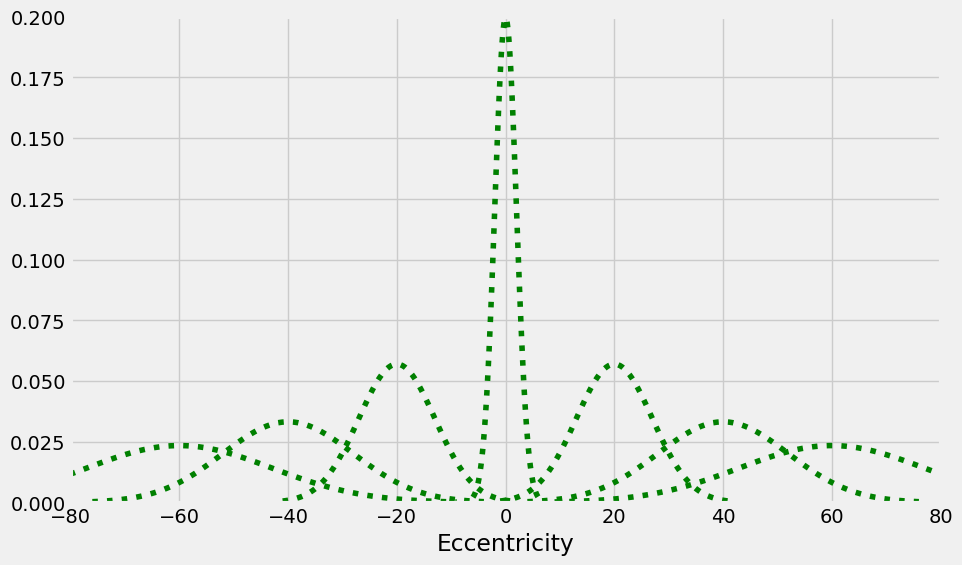

In [4]:

eccentricity = np.arange(-60,70,20)

plt.figure(figsize=(10,6))

for i in eccentricity:
    plot_gaussian(i, fixed_noise+abs(noise_parameter*i), 'g:',f'{i}')

x = plt.xlabel('Eccentricity')

In the figure above it is assumed that the fovea (the gaze location) is at 0 eccentricity. Each distribution then represents the perceived target location probability given that the actual target location is at the centre of the distribution.

So, for example, if the target is at eccentricity 60 then the probability of perceiving it at 60 is about 0.025, whereas if the target is at 20 then the probability of perceiving it at 20 is over 0.05.

Parameter values do not represent the actual human acuity function and are for illustration only.

In [8]:
# Exercise Code : model that returns stochastic percieved location of a target given the true location
import numpy as np

def get_perceived_location(true_loc):
    # 1. absolute of eccentricity
    eccentricity = abs(true_loc)

    # 2. sigma of Gaussian Distribution
    sigma = fixed_noise + noise_parameter * eccentricity

    # 3. Generate a noisy perceived position and return it.
    perceived_loc = np.random.normal(true_loc, sigma)
    return perceived_loc

# 1. Randomly select a real target position between -60 and 60.
true_target = np.random.uniform(-60, 60)

# 2. Calculate the perceived position
perceived_target = get_perceived_location(true_target)

# 3. print and compare
print(f"(True Location): {true_target:.2f}")
print(f"(Perceived Location): {perceived_target:.2f}")
print(f"(Error): {abs(perceived_target - true_target):.2f}")

(True Location): -28.77
(Perceived Location): -29.83
(Error): 1.06


--- Successive Observation Error Reduction ---
Observation Step 1: Mean Error = 7.64
Observation Step 2: Mean Error = 3.12
Observation Step 3: Mean Error = 2.21
Observation Step 4: Mean Error = 2.00
Observation Step 5: Mean Error = 1.97
Observation Step 6: Mean Error = 2.01


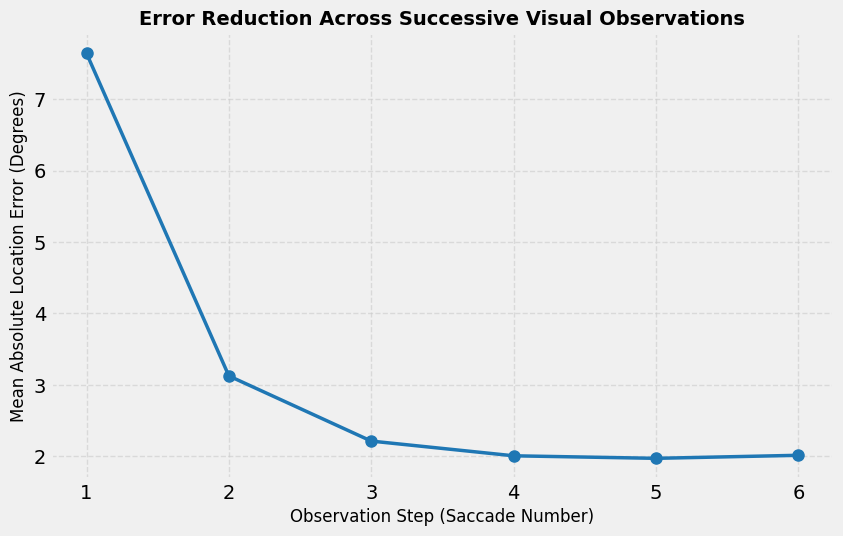

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Define model parameters from the notebook
fixed_noise = 2.0
noise_parameter = 0.25

# ---------------------------------------------------------
# 1. Function to simulate single-trial successive observations
# ---------------------------------------------------------
def simulate_single_trial(true_loc, steps=5):
    """
    Simulates successive gaze moves (saccades) towards a target location.
    Returns a list of location estimation errors for each step.
    """
    gaze_loc = 0.0  # Initial gaze position is at the origin (0)
    error_history = []

    for _ in range(steps):
        # Calculate current retinal eccentricity relative to gaze location
        eccentricity = abs(true_loc - gaze_loc)

        # Calculate noise standard deviation based on eccentricity
        sigma = fixed_noise + noise_parameter * eccentricity

        # Generate stochastic perceived location using Gaussian sampling
        perceived_loc = np.random.normal(loc=true_loc, scale=sigma)

        # Record current estimation error
        error = abs(perceived_loc - true_loc)
        error_history.append(error)

        # Move eyes to the perceived location for the next observation
        gaze_loc = perceived_loc

    return error_history

# ---------------------------------------------------------
# 2. Run multiple simulated trials and compute mean error
# ---------------------------------------------------------
n_trials = 1000
max_steps = 6

# Store errors across all trials
all_trials_errors = np.zeros((n_trials, max_steps))

for i in range(n_trials):
    # Uniformly sample a true target location between -60 and 60 degrees
    true_target = np.random.uniform(-60, 60)
    all_trials_errors[i] = simulate_single_trial(true_target, steps=max_steps)

# Calculate mean error for each observation step across all trials
mean_errors = np.mean(all_trials_errors, axis=0)

# Print average error results
print("--- Successive Observation Error Reduction ---")
for step, err in enumerate(mean_errors, start=1):
    print(f"Observation Step {step}: Mean Error = {err:.2f}")

# ---------------------------------------------------------
# 3. Plot error reduction across successive observations
# ---------------------------------------------------------
plt.figure(figsize=(9, 5.5))
plt.plot(range(1, max_steps + 1), mean_errors, 'o-', color='#1f77b4', linewidth=2.5, markersize=8)

# Chart labels and annotations in English
plt.title('Error Reduction Across Successive Visual Observations', fontsize=14, fontweight='bold')
plt.xlabel('Observation Step (Saccade Number)', fontsize=12)
plt.ylabel('Mean Absolute Location Error (Degrees)', fontsize=12)
plt.xticks(range(1, max_steps + 1))
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

### Exercise

- Build a Python model of human vision which returns the (stochastic) perceived location of a target given the true location.

- Hint:
    1. Use the numpy function random.uniform() to generate a target location between some lower and upper bound of eccentricity.
    2. Use the eccentricity and the function random.normal() to generate an estimate of the target location.

### Advanced exercises

- Assume that the eyes are moved to the perceived location and a new observation is made of the target (which has not moved). Show, through simulated trials, how the error in the perceived location reduces as each successive observation is made.

- Explain why the accuracy increases.

  The accuracy increases across successive observations because each eye movement (saccade) towards the perceived location progressively brings the visual target closer to the fovea, thereby reducing its retinal eccentricity. According to the foveated vision model, the standard deviation of Gaussian spatial noise is directly tied to eccentricity ($\sigma = \text{fixed\_noise} + \text{noise\_parameter} \times \vert{}e\vert{}$); as the target moves closer to the center of gaze, this uncertainty parameter shrinks dramatically. Consequently, subsequent observations are sampled from a much tighter probability distribution with significantly higher visual resolution, allowing location estimates to rapidly converge on the true target position with minimal error.   